Customer Spending Prediction

In [4]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [6]:
# Data Collection

df = pd.read_csv(r'F:\Customer Spending Prediction\datasets\ShopSmart_data.csv')
df

,Age,Annual_Income,Website_Visits,Previous_Purchases,Membership_Type,Preferred_Category,City_Tier,Discount_Used,Amount_Spent
0,46,620358.0,11.0,8,Silver,Beauty,Tier 1,Yes,16924.36
1,27,560886.0,13.0,7,Silver,Fashion,Tier 1,No,16467.52
2,52,866655.0,11.0,9,Bronze,Home,Tier 1,No,19224.61
3,55,816016.0,17.0,9,Silver,Home,Tier 2,Yes,20219.63
4,18,355468.0,14.0,0,Bronze,Home,Tier 3,Yes,7345.37
...,...,...,...,...,...,...,...,...,...
1995,47,557297.0,5.0,6,Gold,Home,Tier 1,No,17423.64
1996,46,1027242.0,11.0,12,Bronze,Fashion,Tier 3,No,19939.64
1997,40,677690.0,15.0,4,Bronze,Fashion,Tier 3,Yes,13397.79
1998,34,565410.0,11.0,8,Silver,Electronics,Tier 3,Yes,17682.11


In [7]:
# EDA

#check top few rows
df.head()

,Age,Annual_Income,Website_Visits,Previous_Purchases,Membership_Type,Preferred_Category,City_Tier,Discount_Used,Amount_Spent
0,46,620358.0,11.0,8,Silver,Beauty,Tier 1,Yes,16924.36
1,27,560886.0,13.0,7,Silver,Fashion,Tier 1,No,16467.52
2,52,866655.0,11.0,9,Bronze,Home,Tier 1,No,19224.61
3,55,816016.0,17.0,9,Silver,Home,Tier 2,Yes,20219.63
4,18,355468.0,14.0,0,Bronze,Home,Tier 3,Yes,7345.37


In [8]:
# check bottom few rows

df.tail()

,Age,Annual_Income,Website_Visits,Previous_Purchases,Membership_Type,Preferred_Category,City_Tier,Discount_Used,Amount_Spent
1995,47,557297.0,5.0,6,Gold,Home,Tier 1,No,17423.64
1996,46,1027242.0,11.0,12,Bronze,Fashion,Tier 3,No,19939.64
1997,40,677690.0,15.0,4,Bronze,Fashion,Tier 3,Yes,13397.79
1998,34,565410.0,11.0,8,Silver,Electronics,Tier 3,Yes,17682.11
1999,65,397581.0,6.0,8,Bronze,Fashion,Tier 3,No,11165.42


In [9]:
# complete info of dataset

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 2000 non-null   int64  
 1   Annual_Income       1984 non-null   float64
 2   Website_Visits      1984 non-null   float64
 3   Previous_Purchases  2000 non-null   int64  
 4   Membership_Type     1984 non-null   str    
 5   Preferred_Category  1984 non-null   str    
 6   City_Tier           2000 non-null   str    
 7   Discount_Used       2000 non-null   str    
 8   Amount_Spent        2000 non-null   float64
dtypes: float64(3), int64(2), str(4)
memory usage: 182.7 KB


In [24]:
# checking missing values

df.isnull().sum()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 2000 non-null   int64  
 1   Annual_Income       2000 non-null   float64
 2   Website_Visits      2000 non-null   float64
 3   Previous_Purchases  2000 non-null   int64  
 4   Membership_Type     2000 non-null   str    
 5   Preferred_Category  2000 non-null   str    
 6   City_Tier           2000 non-null   str    
 7   Discount_Used       2000 non-null   str    
 8   Amount_Spent        2000 non-null   float64
dtypes: float64(3), int64(2), str(4)
memory usage: 182.4 KB


In [ ]:
# Handling nan values

avg_income = round(df["Annual_Income"].mean())
avg_web_visits = round(df["Website_Visits"].mean())
freq_category = df["Preferred_Category"].mode()[0]
freq_membership = df["Membership_Type"].mode()[0]

df["Annual_Income"] = df["Annual_Income"].fillna(avg_income, inplace=True)
df["Website_Visits"] = df["Website_Visits"].fillna(avg_web_visits, inplace=True)
df["Preferred_Category"] = df["Preferred_Category"].fillna(freq_category, inplace=True)
df["Membership_Type"] = df["Membership_Type"].fillna(freq_membership, inplace=True)


In [23]:
# check duplicate rows

df[df.duplicated()]

,Age,Annual_Income,Website_Visits,Previous_Purchases,Membership_Type,Preferred_Category,City_Tier,Discount_Used,Amount_Spent


In [ ]:
# summary of data

df.describe()

,Age,Annual_Income,Website_Visits,Previous_Purchases,Amount_Spent
count,2000.000000,2.000000e+03,2000.00000,2000.0000,2000.000000
mean,40.917500,7.525418e+05,9.95650,6.9655,17505.982405
std,12.780116,2.728578e+05,3.09134,2.6235,3866.061235
min,18.000000,1.800000e+05,2.00000,0.0000,6875.410000
25%,32.000000,5.605328e+05,8.00000,5.0000,14864.417500
50%,41.000000,7.520560e+05,10.00000,7.0000,17381.955000
75%,50.000000,9.346820e+05,12.00000,9.0000,19927.317500
max,65.000000,1.604606e+06,20.00000,16.0000,35371.200000


In [27]:
# check numeric columns

num_cols = []
for col in df.columns:
    if df[col].dtype != "str":
        num_cols.append(col)
df[num_cols]       

,Age,Annual_Income,Website_Visits,Previous_Purchases,Amount_Spent
0,46,620358.0,11.0,8,16924.36
1,27,560886.0,13.0,7,16467.52
2,52,866655.0,11.0,9,19224.61
3,55,816016.0,17.0,9,20219.63
4,18,355468.0,14.0,0,7345.37
...,...,...,...,...,...
1995,47,557297.0,5.0,6,17423.64
1996,46,1027242.0,11.0,12,19939.64
1997,40,677690.0,15.0,4,13397.79
1998,34,565410.0,11.0,8,17682.11


This data needs to be scaled

In [28]:
# check object columns


for col in df.columns:
    if df[col].dtype == "str":
        print(col,"      :",list(df[col].unique()))
        

Membership_Type       : ['Silver', 'Bronze', 'Gold']
Preferred_Category       : ['Beauty', 'Fashion', 'Home', 'Electronics']
City_Tier       : ['Tier 1', 'Tier 2', 'Tier 3']
Discount_Used       : ['Yes', 'No']


These columns needs to be encoded

In [29]:
df

,Age,Annual_Income,Website_Visits,Previous_Purchases,Membership_Type,Preferred_Category,City_Tier,Discount_Used,Amount_Spent
0,46,620358.0,11.0,8,Silver,Beauty,Tier 1,Yes,16924.36
1,27,560886.0,13.0,7,Silver,Fashion,Tier 1,No,16467.52
2,52,866655.0,11.0,9,Bronze,Home,Tier 1,No,19224.61
3,55,816016.0,17.0,9,Silver,Home,Tier 2,Yes,20219.63
4,18,355468.0,14.0,0,Bronze,Home,Tier 3,Yes,7345.37
...,...,...,...,...,...,...,...,...,...
1995,47,557297.0,5.0,6,Gold,Home,Tier 1,No,17423.64
1996,46,1027242.0,11.0,12,Bronze,Fashion,Tier 3,No,19939.64
1997,40,677690.0,15.0,4,Bronze,Fashion,Tier 3,Yes,13397.79
1998,34,565410.0,11.0,8,Silver,Electronics,Tier 3,Yes,17682.11


<Axes: xlabel='Preferred_Category', ylabel='Amount_Spent'>

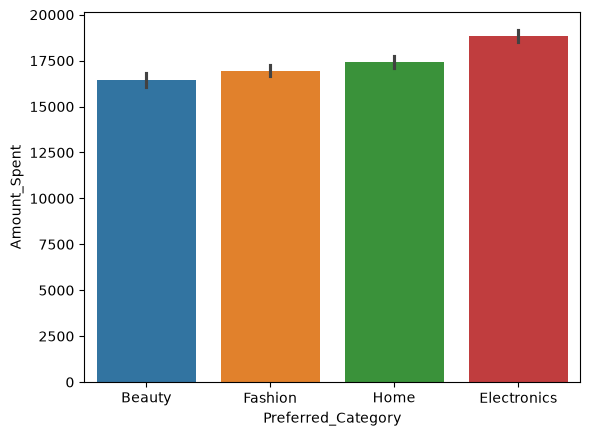

In [33]:
sns.barplot(x="Preferred_Category", y="Amount_Spent", data=df,hue= "Preferred_Category")

Customer is spending more on Electronics

<Axes: xlabel='Age', ylabel='Amount_Spent'>

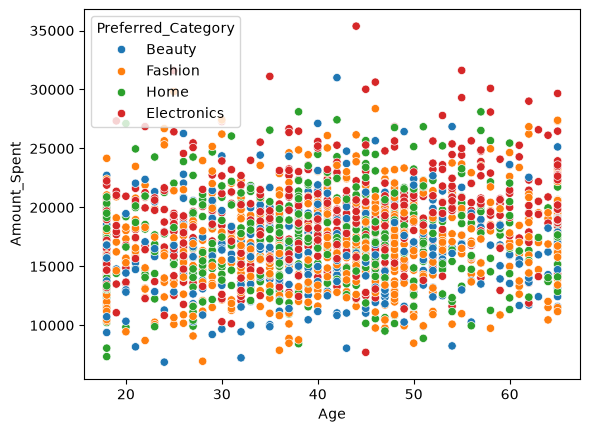

In [34]:
sns.scatterplot(x="Age", y="Amount_Spent", data=df, hue="Preferred_Category")

Most of the customers are spending in between 10000 to 25000

<Axes: xlabel='Website_Visits', ylabel='Count'>

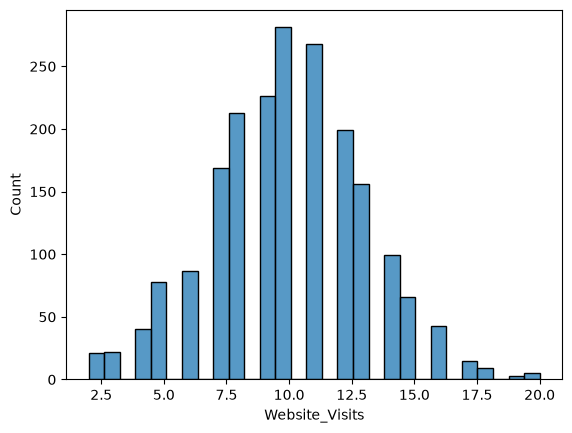

In [36]:
sns.histplot(x="Website_Visits",data = df)

most of the customers visiting website 7 to 13 times.

<Axes: xlabel='Membership_Type', ylabel='Amount_Spent'>

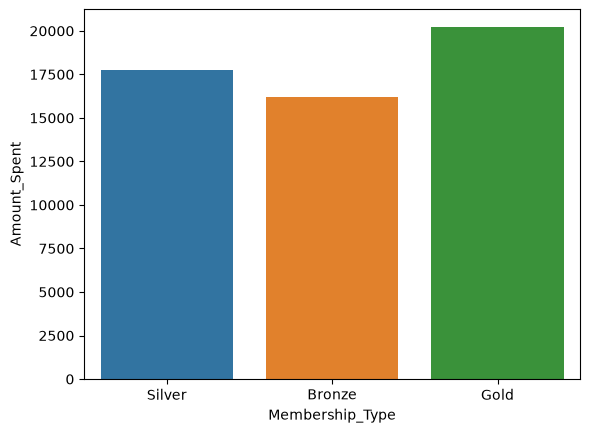

In [38]:
sns.barplot(x="Membership_Type", y="Amount_Spent", data=df,hue= "Membership_Type",errorbar=None)

In [41]:
corr = df[num_cols].corr()
corr

,Age,Annual_Income,Website_Visits,Previous_Purchases,Amount_Spent
Age,1.000000,0.009783,-0.005498,0.010538,0.146029
Annual_Income,0.009783,1.000000,0.041128,0.048352,0.752104
Website_Visits,-0.005498,0.041128,1.000000,0.011164,0.133853
Previous_Purchases,0.010538,0.048352,0.011164,1.000000,0.389283
Amount_Spent,0.146029,0.752104,0.133853,0.389283,1.000000


<Axes: >

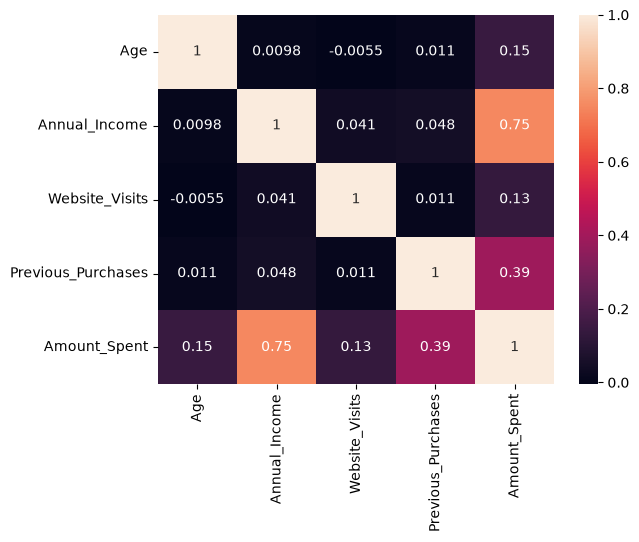

In [ ]:
# find correlation between numeric columns
sns.heatmap(corr, annot=True)

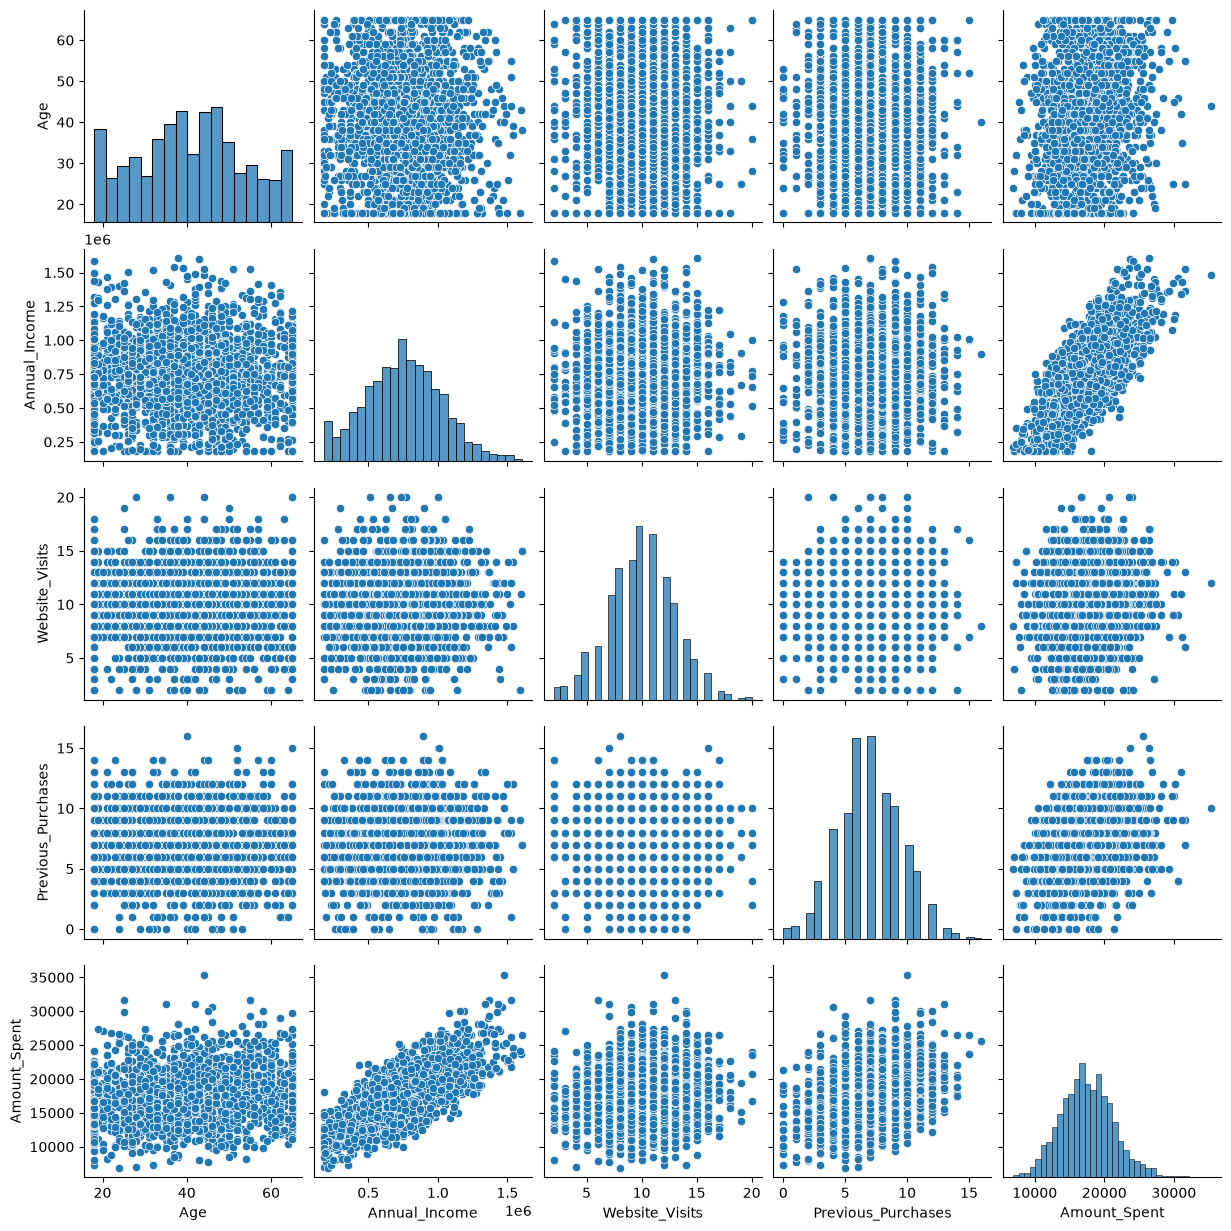

In [ ]:
# find correlation between numeric columns using pairplot
sns.pairplot(df)

Model Pipeline

In [59]:
# Divide the data into input and output features

X = df.drop("Amount_Spent", axis=1)
y = df.Amount_Spent

In [60]:
# training and testing data split

Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=42)

In [61]:
#separate numeric and categorical columns

num_cols = Xtrain.select_dtypes(include="number").columns
cat_cols = Xtrain.select_dtypes(include="str").columns

In [62]:
models = {"Linear Regression":Pipeline([("preprocessor",ColumnTransformer([("encoder",OneHotEncoder(),cat_cols),
                                                                            ("scaler",StandardScaler(),num_cols)])),
                                        ("model",LinearRegression())]),
        "Ridge Regression":Pipeline([("preprocessor",ColumnTransformer([("encoder",OneHotEncoder(),cat_cols),
                                                                            ("scaler",StandardScaler(),num_cols)])),
                                        ("model",Ridge())]),
        "Lasso Regression":Pipeline([("preprocessor",ColumnTransformer([("encoder",OneHotEncoder(),cat_cols),
                                                                            ("scaler",StandardScaler(),num_cols)])),
                                        ("model",Lasso(alpha=100))]),
        "Decision Tree":Pipeline([("preprocessor",ColumnTransformer([("encoder",OneHotEncoder(),cat_cols),
                                                                            ("scaler",StandardScaler(),num_cols)])),
                                        ("model",DecisionTreeRegressor(max_depth=10))]),
        "Random Forest":Pipeline([("preprocessor",ColumnTransformer([("encoder",OneHotEncoder(),cat_cols),
                                                                            ("scaler",StandardScaler(),num_cols)])),
                                        ("model",RandomForestRegressor(n_estimators=100,max_depth=7,random_state=42))])}

In [65]:
# multi- models-training

model_perf = {}
for model_name, pipeline in models.items():
    pipeline.fit(Xtrain, ytrain)
    y_pred = pipeline.predict(Xtest)
    r2 = r2_score(ytest, y_pred)
    mse = mean_squared_error(ytest, y_pred)
    mae = mean_absolute_error(ytest, y_pred)
    model_perf[model_name] = {"R2": r2, "MSE": mse, "MAE": mae}

In [ ]:
perf_df = pd.DataFrame(model_perf)
perf_df

,Linear Regression,Ridge Regression,Lasso Regression,Decision Tree,Random Forest
R2,0.953367,0.953405,0.927361,7.399129e-01,8.601341e-01
MSE,596807.514906,596319.327414,929620.253469,3.328560e+06,1.789985e+06
MAE,597.016341,596.590982,770.133504,1.387319e+03,1.073937e+03


In [83]:
# fetch best model

best_model_data = max(model_perf.items(), key=lambda d: d[1]["R2"])
best_model_name = best_model_data[0]
best_model_name
print(best_model_data)
best_pipeline = models[best_model_name]

('Ridge Regression', {'R2': 0.9534047900428712, 'MSE': 596319.3274144304, 'MAE': 596.5909824553383})


In [81]:
# save the best model pipeline

import pickle
with open(r"F:\Customer Spending Prediction\best_model_pipeline.pkl", "wb") as f:
    pickle.dump(best_pipeline, f)

In [82]:
# save the cleaned data

df.to_csv(r"F:\Customer Spending Prediction\datasets\ShopSmart_data_cleaned.csv", index=False)

In [84]:
Xtrain.columns

Index(['Age', 'Annual_Income', 'Website_Visits', 'Previous_Purchases',
       'Membership_Type', 'Preferred_Category', 'City_Tier', 'Discount_Used'],
      dtype='str')